In [6]:

import zipfile
import os

zip_path = "student_academic_insight_starter.zip"

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall("/content/academic_insight")

data_dir = "/content/academic_insight/student_academic_insight"

print(os.listdir(data_dir))



['assessments.csv', 'engagement.csv', '.ipynb_checkpoints', 'students.csv', 'attendance.csv', 'courses.csv']


In [7]:

import pandas as pd
import os

students = pd.read_csv(f"{data_dir}/students.csv")
attendance = pd.read_csv(f"{data_dir}/attendance.csv")
assessments = pd.read_csv(f"{data_dir}/assessments.csv")
engagement = pd.read_csv(f"{data_dir}/engagement.csv")
courses = pd.read_csv(f"{data_dir}/courses.csv")

datasets = {
    "Students": students,
    "Attendance": attendance,
    "Assessments": assessments,
    "Engagement": engagement,
    "Courses": courses
}

for name, df in datasets.items():
    print(f"\n--- {name} ---")
    print("Shape:", df.shape)
    print("\nData types:")
    print(df.dtypes)
    print("\nMissing values:")
    print(df.isnull().sum())
    print("Duplicate rows:", df.duplicated().sum())
    display(df.head())



--- Students ---
Shape: (240, 4)

Data types:
student_id           object
programme            object
semester              int64
demographic_group    object
dtype: object

Missing values:
student_id           0
programme            0
semester             0
demographic_group    0
dtype: int64
Duplicate rows: 0


,student_id,programme,semester,demographic_group
0,STU0001,IT,4,Group B
1,STU0002,AIML,1,Group A
2,STU0003,CSE,6,Group A
3,STU0004,CSE,6,Group C
4,STU0005,CSE,1,Group A



--- Attendance ---
Shape: (1214, 4)

Data types:
student_id           object
course_code          object
sessions_held         int64
sessions_attended     int64
dtype: object

Missing values:
student_id           0
course_code          0
sessions_held        0
sessions_attended    0
dtype: int64
Duplicate rows: 14


,student_id,course_code,sessions_held,sessions_attended
0,STU0001,MA101,27,18
1,STU0001,AI201,35,22
2,STU0001,EC101,32,20
3,STU0001,CS102,33,17
4,STU0002,CS204,31,25



--- Assessments ---
Shape: (1214, 6)

Data types:
student_id           object
course_code          object
quiz_score          float64
assignment_score    float64
test_score          float64
lab_score           float64
dtype: object

Missing values:
student_id           0
course_code          0
quiz_score          53
assignment_score    39
test_score          41
lab_score           52
dtype: int64
Duplicate rows: 14


,student_id,course_code,quiz_score,assignment_score,test_score,lab_score
0,STU0001,MA101,68.357250,NaN,75.027512,73.710953
1,STU0001,AI201,53.846211,84.488096,80.779646,83.375375
2,STU0001,EC101,58.549891,68.764239,79.726161,85.093670
3,STU0001,CS102,64.429367,61.460681,67.204196,81.131731
4,STU0002,CS204,57.741263,80.247782,86.928125,NaN



--- Engagement ---
Shape: (1214, 7)

Data types:
student_id               object
course_code              object
lms_logins                int64
submissions_completed     int64
submissions_expected      int64
late_submissions          int64
lms_activity_count        int64
dtype: object

Missing values:
student_id               0
course_code              0
lms_logins               0
submissions_completed    0
submissions_expected     0
late_submissions         0
lms_activity_count       0
dtype: int64
Duplicate rows: 14


,student_id,course_code,lms_logins,submissions_completed,submissions_expected,late_submissions,lms_activity_count
0,STU0001,MA101,30,3,9,6,70
1,STU0001,AI201,26,2,8,3,62
2,STU0001,EC101,34,3,6,2,78
3,STU0001,CS102,39,6,10,5,79
4,STU0002,CS204,27,3,5,1,37



--- Courses ---
Shape: (8, 5)

Data types:
course_code    object
course_name    object
course_type    object
credits         int64
faculty        object
dtype: object

Missing values:
course_code    0
course_name    0
course_type    0
credits        0
faculty        0
dtype: int64
Duplicate rows: 0


,course_code,course_name,course_type,credits,faculty
0,CS101,Programming Fundamentals,Core,4,Faculty A
1,CS102,Data Structures,Core,4,Faculty B
2,CS103,Database Systems,Core,3,Faculty C
3,AI201,Machine Learning,Elective,3,Faculty D
4,MA101,Applied Mathematics,Core,4,Faculty E


In [8]:

# 1. Check repeated student-course combinations
for name, df in {
    "Attendance": attendance,
    "Assessments": assessments,
    "Engagement": engagement
}.items():
    print(f"\n--- {name}: Duplicate Keys ---")

    duplicate_keys = df[
        df.duplicated(
            subset=["student_id", "course_code"],
            keep=False
        )
    ].sort_values(["student_id", "course_code"])

    print("Rows involved in repeated keys:", len(duplicate_keys))
    display(duplicate_keys.head(10))


# 2. Inspect course codes in all datasets
for name, df in {
    "Attendance": attendance,
    "Assessments": assessments,
    "Engagement": engagement,
    "Courses": courses
}.items():
    print(f"\n{name} course codes:")
    print(sorted(df["course_code"].astype(str).unique()))



--- Attendance: Duplicate Keys ---
Rows involved in repeated keys: 28


,student_id,course_code,sessions_held,sessions_attended
17,STU0004,MA101,26,23
1207,STU0004,MA101,26,23
134,STU0027,CS101,28,19
1202,STU0027,CS101,28,19
166,STU0034,CS102,35,28
1206,STU0034,CS102,35,28
262,STU0053,CS102,29,24
1213,STU0053,CS102,29,24
350,STU0071,MA101,28,12
1211,STU0071,MA101,28,12



--- Assessments: Duplicate Keys ---
Rows involved in repeated keys: 28


,student_id,course_code,quiz_score,assignment_score,test_score,lab_score
17,STU0004,MA101,70.224444,54.466434,61.805060,55.550223
1207,STU0004,MA101,70.224444,54.466434,61.805060,55.550223
134,STU0027,CS101,65.078255,67.843711,68.893601,86.773056
1202,STU0027,CS101,65.078255,67.843711,68.893601,86.773056
166,STU0034,CS102,57.139689,69.249418,88.892627,83.135159
1206,STU0034,CS102,57.139689,69.249418,88.892627,83.135159
262,STU0053,CS102,31.862964,57.923791,42.106992,59.982500
1213,STU0053,CS102,31.862964,57.923791,42.106992,59.982500
350,STU0071,MA101,53.846735,53.170226,48.068667,53.941449
1211,STU0071,MA101,53.846735,53.170226,48.068667,53.941449



--- Engagement: Duplicate Keys ---
Rows involved in repeated keys: 28


,student_id,course_code,lms_logins,submissions_completed,submissions_expected,late_submissions,lms_activity_count
17,STU0004,MA101,32,2,6,5,41
1207,STU0004,MA101,32,2,6,5,41
134,STU0027,CS101,38,3,7,3,72
1202,STU0027,CS101,38,3,7,3,72
166,STU0034,CS102,22,4,7,1,52
1206,STU0034,CS102,22,4,7,1,52
262,STU0053,CS102,33,3,10,4,60
1213,STU0053,CS102,33,3,10,4,60
350,STU0071,MA101,21,1,9,3,65
1211,STU0071,MA101,21,1,9,3,65



Attendance course codes:
['AI201', 'CS 102', 'CS-101', 'CS101', 'CS102', 'CS103', 'CS204', 'CS204 ', 'DA202', 'DBS103', 'EC-101', 'EC101', 'IT202', 'MA101', 'ML-201']

Assessments course codes:
['AI201', 'CS-101', 'CS101', 'CS102', 'CS103', 'CS204', 'DA202', 'DBS103', 'EC-101', 'EC101', 'IT202', 'MA101', 'MATH101', 'ML-201']

Engagement course codes:
['AI201', 'CS-101', 'CS101', 'CS102', 'CS103', 'CS204', 'DBS103', 'EC-101', 'EC101', 'IT202', 'MA101', 'MATH101']

Courses course codes:
['AI201', 'CS101', 'CS102', 'CS103', 'CS204', 'EC101', 'IT202', 'MA101']


In [9]:

score_cols = [
    "quiz_score",
    "assignment_score",
    "test_score",
    "lab_score"
]

for col in score_cols:
    invalid = assessments[
        assessments[col].notna()
        & ~assessments[col].between(0, 100)
    ]

    print(f"\n{col}")
    print("Invalid values:", len(invalid))
    display(invalid[["student_id", "course_code", col]])






quiz_score
Invalid values: 0


,student_id,course_code,quiz_score



assignment_score
Invalid values: 0


,student_id,course_code,assignment_score



test_score
Invalid values: 3


,student_id,course_code,test_score
524,STU0105,CS102,125.0
692,STU0139,EC101,142.0
1135,STU0228,EC-101,-8.0



lab_score
Invalid values: 0


,student_id,course_code,lab_score


In [10]:

# Attendance validation
invalid_attendance = attendance[
    (attendance["sessions_attended"] > attendance["sessions_held"])
    | (attendance["sessions_attended"] < 0)
    | (attendance["sessions_held"] <= 0)
]

print("Invalid attendance records:", len(invalid_attendance))
display(invalid_attendance.head(10))

# Engagement validation
invalid_submissions = engagement[
    (engagement["submissions_completed"] < 0)
    | (engagement["submissions_expected"] <= 0)
    | (engagement["submissions_completed"] >
       engagement["submissions_expected"])
    | (engagement["late_submissions"] < 0)
]

print("Potentially invalid submission records:", len(invalid_submissions))
display(invalid_submissions.head(10))


Invalid attendance records: 0


,student_id,course_code,sessions_held,sessions_attended


Potentially invalid submission records: 0


,student_id,course_code,lms_logins,submissions_completed,submissions_expected,late_submissions,lms_activity_count


# **DATA CLEANING**

In [11]:

# STEP 1: Preserve the original raw data
attendance_raw = attendance.copy()
assessments_raw = assessments.copy()
engagement_raw = engagement.copy()
courses_raw = courses.copy()

# STEP 2: Standardize course codes
course_map = {
    "CS-101": "CS101",
    "CS 102": "CS102",
    "DBS103": "CS103",
    "ML-201": "AI201",
    "MATH101": "MA101",
    "EC-101": "EC101",
    "DA202": "IT202"
}

def standardize_codes(df):
    df = df.copy()
    df["course_code"] = (
        df["course_code"]
        .astype(str)
        .str.strip()
        .str.upper()
        .replace(course_map)
    )
    return df

attendance_clean = standardize_codes(attendance_raw)
assessments_clean = standardize_codes(assessments_raw)
engagement_clean = standardize_codes(engagement_raw)
courses_clean = standardize_codes(courses_raw)

# STEP 3: Remove exact duplicate rows
for name, df in [
    ("Attendance", attendance_clean),
    ("Assessments", assessments_clean),
    ("Engagement", engagement_clean)
]:
    before = len(df)
    df.drop_duplicates(inplace=True)
    print(f"{name}: {before - len(df)} exact duplicate rows removed")
    print(f"Rows remaining: {len(df)}")

# STEP 4: Check for repeated student-course keys
for name, df in [
    ("Attendance", attendance_clean),
    ("Assessments", assessments_clean),
    ("Engagement", engagement_clean)
]:
    duplicate_keys = df.duplicated(
        subset=["student_id", "course_code"]
    ).sum()

    print(f"{name}: repeated student-course keys = {duplicate_keys}")

# STEP 5: Validate assessment scores
score_cols = [
    "quiz_score",
    "assignment_score",
    "test_score",
    "lab_score"
]

for col in score_cols:
    invalid_mask = (
        assessments_clean[col].notna()
        & ~assessments_clean[col].between(0, 100)
    )

    print(f"{col}: invalid scores = {invalid_mask.sum()}")

    # Invalid scores are marked missing for investigation.
    assessments_clean.loc[invalid_mask, col] = float("nan")

print("\nCleaning checks completed.")


Attendance: 14 exact duplicate rows removed
Rows remaining: 1200
Assessments: 14 exact duplicate rows removed
Rows remaining: 1200
Engagement: 14 exact duplicate rows removed
Rows remaining: 1200
Attendance: repeated student-course keys = 0
Assessments: repeated student-course keys = 0
Engagement: repeated student-course keys = 0
quiz_score: invalid scores = 0
assignment_score: invalid scores = 0
test_score: invalid scores = 3
lab_score: invalid scores = 0

Cleaning checks completed.


In [12]:

cleaned_datasets = {
    "Attendance": attendance_clean,
    "Assessments": assessments_clean,
    "Engagement": engagement_clean
}

for name, df in cleaned_datasets.items():
    print(f"\n{name}")
    print("Shape:", df.shape)
    print("Exact duplicate rows:", df.duplicated().sum())
    print(
        "Duplicate student-course keys:",
        df.duplicated(["student_id", "course_code"]).sum()
    )

print("\nMissing assessment values after validation:")
print(assessments_clean[score_cols].isna().sum())

print("\nCourse codes not found in course master:")
valid_codes = set(courses_clean["course_code"])
for name, df in cleaned_datasets.items():
    unknown = sorted(set(df["course_code"]) - valid_codes)
    print(name, unknown)



Attendance
Shape: (1200, 4)
Exact duplicate rows: 0
Duplicate student-course keys: 0

Assessments
Shape: (1200, 6)
Exact duplicate rows: 0
Duplicate student-course keys: 0

Engagement
Shape: (1200, 7)
Exact duplicate rows: 0
Duplicate student-course keys: 0

Missing assessment values after validation:
quiz_score          53
assignment_score    39
test_score          42
lab_score           52
dtype: int64

Course codes not found in course master:
Attendance []
Assessments []
Engagement []


In [13]:

# Step 1: Check whether the three datasets contain matching student-course pairs
attendance_keys = set(
    zip(attendance_clean["student_id"], attendance_clean["course_code"])
)
assessment_keys = set(
    zip(assessments_clean["student_id"], assessments_clean["course_code"])
)
engagement_keys = set(
    zip(engagement_clean["student_id"], engagement_clean["course_code"])
)

print("Attendance vs Assessments:", attendance_keys == assessment_keys)
print("Attendance vs Engagement:", attendance_keys == engagement_keys)

# Step 2: Merge attendance, assessments and engagement
academic_data = attendance_clean.merge(
    assessments_clean,
    on=["student_id", "course_code"],
    how="outer",
    validate="one_to_one",
    indicator="_assessment_merge"
)

print("\nAssessment merge status:")
print(academic_data["_assessment_merge"].value_counts())

academic_data.drop(columns="_assessment_merge", inplace=True)

academic_data = academic_data.merge(
    engagement_clean,
    on=["student_id", "course_code"],
    how="outer",
    validate="one_to_one",
    indicator="_engagement_merge"
)

print("\nEngagement merge status:")
print(academic_data["_engagement_merge"].value_counts())

academic_data.drop(columns="_engagement_merge", inplace=True)

# Step 3: Add student information and course information
academic_data = academic_data.merge(
    students,
    on="student_id",
    how="left",
    validate="many_to_one"
)

academic_data = academic_data.merge(
    courses_clean,
    on="course_code",
    how="left",
    validate="many_to_one",
    suffixes=("", "_course")
)

# Step 4: Inspect the merged dataset
print("\nFinal merged dataset shape:", academic_data.shape)
print("Unique students:", academic_data["student_id"].nunique())
print("Unique courses:", academic_data["course_code"].nunique())
print("Duplicate student-course records:",
      academic_data.duplicated(["student_id", "course_code"]).sum())

print("\nColumns:")
print(academic_data.columns.tolist())

print("\nFirst five rows:")
display(academic_data.head())

print("\nMissing values:")
display(
    academic_data.isnull().sum()
    .sort_values(ascending=False)
    .to_frame("Missing_Count")
)


Attendance vs Assessments: True
Attendance vs Engagement: True

Assessment merge status:
_assessment_merge
both          1200
left_only        0
right_only       0
Name: count, dtype: int64

Engagement merge status:
_engagement_merge
both          1200
left_only        0
right_only       0
Name: count, dtype: int64

Final merged dataset shape: (1200, 20)
Unique students: 240
Unique courses: 8
Duplicate student-course records: 0

Columns:
['student_id', 'course_code', 'sessions_held', 'sessions_attended', 'quiz_score', 'assignment_score', 'test_score', 'lab_score', 'lms_logins', 'submissions_completed', 'submissions_expected', 'late_submissions', 'lms_activity_count', 'programme', 'semester', 'demographic_group', 'course_name', 'course_type', 'credits', 'faculty']

First five rows:


,student_id,course_code,sessions_held,sessions_attended,quiz_score,assignment_score,test_score,lab_score,lms_logins,submissions_completed,submissions_expected,late_submissions,lms_activity_count,programme,semester,demographic_group,course_name,course_type,credits,faculty
0,STU0001,AI201,35,22,53.846211,84.488096,80.779646,83.375375,26,2,8,3,62,IT,4,Group B,Machine Learning,Elective,3,Faculty D
1,STU0001,CS102,33,17,64.429367,61.460681,67.204196,81.131731,39,6,10,5,79,IT,4,Group B,Data Structures,Core,4,Faculty B
2,STU0001,EC101,32,20,58.549891,68.764239,79.726161,85.093670,34,3,6,2,78,IT,4,Group B,Digital Systems,Core,3,Faculty G
3,STU0001,MA101,27,18,68.357250,NaN,75.027512,73.710953,30,3,9,6,70,IT,4,Group B,Applied Mathematics,Core,4,Faculty E
4,STU0002,AI201,38,27,52.512800,66.272490,40.293402,69.073166,33,0,7,9,55,AIML,1,Group A,Machine Learning,Elective,3,Faculty D



Missing values:


,Missing_Count
quiz_score,53
lab_score,52
test_score,42
assignment_score,39
sessions_attended,0
sessions_held,0
course_code,0
student_id,0
lms_logins,0
submissions_completed,0


In [14]:

import numpy as np
import pandas as pd

# 1. Examine missing assessment values
score_cols = [
    "quiz_score",
    "assignment_score",
    "test_score",
    "lab_score"
]

print("Missing assessment values (%)")
display(
    (academic_data[score_cols].isna().mean() * 100)
    .round(2)
    .to_frame("Missing_Percentage")
)

print("\nNumber of available assessment scores per record")
display(
    academic_data[score_cols]
    .notna()
    .sum()
    .value_counts()
    .sort_index()
    .rename_axis("Available_Scores")
    .to_frame("Record_Count")
)

# 2. Create a separate analysis dataset
analysis_data = academic_data.copy()

# 3. Attendance percentage
analysis_data["attendance_rate"] = np.where(
    analysis_data["sessions_held"] > 0,
    100 * analysis_data["sessions_attended"]
    / analysis_data["sessions_held"],
    np.nan
)

# 4. Assignment completion percentage
analysis_data["submission_completion_rate"] = np.where(
    analysis_data["submissions_expected"] > 0,
    100 * analysis_data["submissions_completed"]
    / analysis_data["submissions_expected"],
    np.nan
)

# 5. Late submission percentage
analysis_data["late_submission_rate"] = np.where(
    analysis_data["submissions_completed"] > 0,
    100 * analysis_data["late_submissions"]
    / analysis_data["submissions_completed"],
    np.nan
)

# 6. Calculate academic average only when at least 2 marks are available
analysis_data["available_score_count"] = (
    analysis_data[score_cols].notna().sum(axis=1)
)

analysis_data["academic_average"] = (
    analysis_data[score_cols].mean(axis=1)
)

analysis_data.loc[
    analysis_data["available_score_count"] < 2,
    "academic_average"
] = np.nan

# 7. Flag records for review using transparent thresholds
analysis_data["low_attendance_flag"] = (
    analysis_data["attendance_rate"] < 75
)

analysis_data["low_completion_flag"] = (
    analysis_data["submission_completion_rate"] < 60
)

analysis_data["low_score_flag"] = (
    analysis_data["academic_average"] < 50
)

# This is a screening indicator, not a definitive risk diagnosis
analysis_data["support_review_flag"] = (
    analysis_data[
        [
            "low_attendance_flag",
            "low_completion_flag",
            "low_score_flag"
        ]
    ].any(axis=1)
)

# 8. Summary of the new indicators
indicator_cols = [
    "attendance_rate",
    "submission_completion_rate",
    "late_submission_rate",
    "academic_average"
]

print("\nIndicator summary")
display(analysis_data[indicator_cols].describe().round(2))

print("\nRecords flagged for support review:")
print(
    analysis_data["support_review_flag"]
    .value_counts()
    .rename(index={True: "Flagged", False: "Not flagged"})
)

print("\nPreview")
display(
    analysis_data[
        [
            "student_id",
            "course_code",
            "attendance_rate",
            "submission_completion_rate",
            "academic_average",
            "support_review_flag"
        ]
    ].head(10).round(2)
)


Missing assessment values (%)


,Missing_Percentage
quiz_score,4.42
assignment_score,3.25
test_score,3.50
lab_score,4.33



Number of available assessment scores per record


,Record_Count
Available_Scores,
1147,1
1148,1
1158,1
1161,1



Indicator summary


,attendance_rate,submission_completion_rate,late_submission_rate,academic_average
count,1200.00,1200.00,1181.00,1200.00
mean,77.22,55.05,85.92,71.70
std,12.53,21.14,115.70,11.63
min,36.00,0.00,0.00,36.00
25%,68.75,40.00,22.22,62.98
50%,77.42,55.56,50.00,72.20
75%,86.28,70.00,100.00,80.11
max,100.00,100.00,1200.00,100.00



Records flagged for support review:
support_review_flag
Flagged        842
Not flagged    358
Name: count, dtype: int64

Preview


,student_id,course_code,attendance_rate,submission_completion_rate,academic_average,support_review_flag
0,STU0001,AI201,62.86,25.00,75.62,True
1,STU0001,CS102,51.52,60.00,68.56,True
2,STU0001,EC101,62.50,50.00,73.03,True
3,STU0001,MA101,66.67,33.33,72.37,True
4,STU0002,AI201,71.05,0.00,57.04,True
5,STU0002,CS102,83.33,40.00,71.99,True
6,STU0002,CS103,87.88,54.55,73.15,True
7,STU0002,CS204,80.65,60.00,74.97,False
8,STU0002,EC101,67.65,50.00,50.82,True
9,STU0003,AI201,82.14,81.82,77.17,False


In [15]:

# 1. Correctly count available assessment scores
available_score_count = academic_data[score_cols].notna().sum(axis=1)

print("Records by number of available assessment scores:")
display(
    available_score_count.value_counts()
    .sort_index()
    .rename_axis("Available_Scores")
    .to_frame("Record_Count")
)

# 2. Inspect late-submission data before calculating its rate
late_check = analysis_data[
    [
        "student_id",
        "course_code",
        "submissions_completed",
        "submissions_expected",
        "late_submissions"
    ]
].copy()

print("\nLate-submission summary:")
display(
    late_check[
        [
            "submissions_completed",
            "submissions_expected",
            "late_submissions"
        ]
    ].describe().round(2)
)

# A late submission should normally be part of the completed submissions
impossible_late = (
    late_check["late_submissions"]
    > late_check["submissions_completed"]
)

print("\nRows where late submissions exceed completed submissions:",
      impossible_late.sum())

print("\nExamples to inspect:")
display(late_check.loc[impossible_late].head(15))

# 3. Count records where completed submissions exceed expected submissions
impossible_completion = (
    late_check["submissions_completed"]
    > late_check["submissions_expected"]
)

print("\nRows where completed submissions exceed expected submissions:",
      impossible_completion.sum())

# 4. Check the support-review flag
print("\nSupport-review flag values:")
print(analysis_data["support_review_flag"].value_counts(dropna=False))


Records by number of available assessment scores:


,Record_Count
Available_Scores,
2,11
3,164
4,1025



Late-submission summary:


,submissions_completed,submissions_expected,late_submissions
count,1200.00,1200.00,1200.00
mean,4.68,8.51,2.94
std,2.25,2.30,2.29
min,0.00,5.00,0.00
25%,3.00,7.00,1.00
50%,4.00,8.00,3.00
75%,6.00,10.00,4.00
max,12.00,12.00,12.00



Rows where late submissions exceed completed submissions: 292

Examples to inspect:


,student_id,course_code,submissions_completed,submissions_expected,late_submissions
0,STU0001,AI201,2,8,3
3,STU0001,MA101,3,9,6
4,STU0002,AI201,0,7,9
17,STU0004,EC101,1,11,2
19,STU0004,MA101,2,6,5
20,STU0005,CS102,2,7,4
21,STU0005,CS103,5,12,9
27,STU0006,IT202,1,11,12
30,STU0007,CS103,5,9,6
31,STU0007,IT202,4,11,6



Rows where completed submissions exceed expected submissions: 0

Support-review flag values:
support_review_flag
True     842
False    358
Name: count, dtype: int64


Records excluded from late-rate calculation: 292
Valid late-rate records: 907
Mean late-submission rate among valid records: 42.68 %

Unique students with at least one support-review flag: 238 out of 240


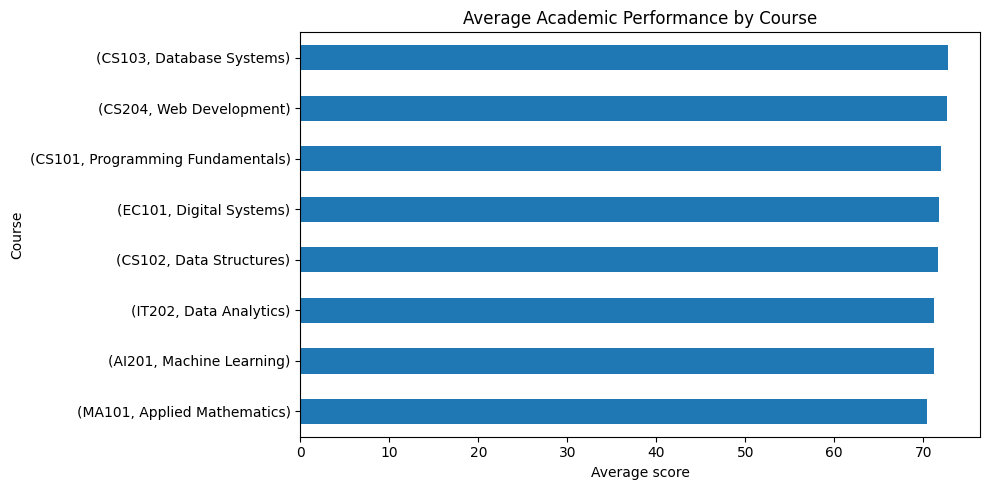

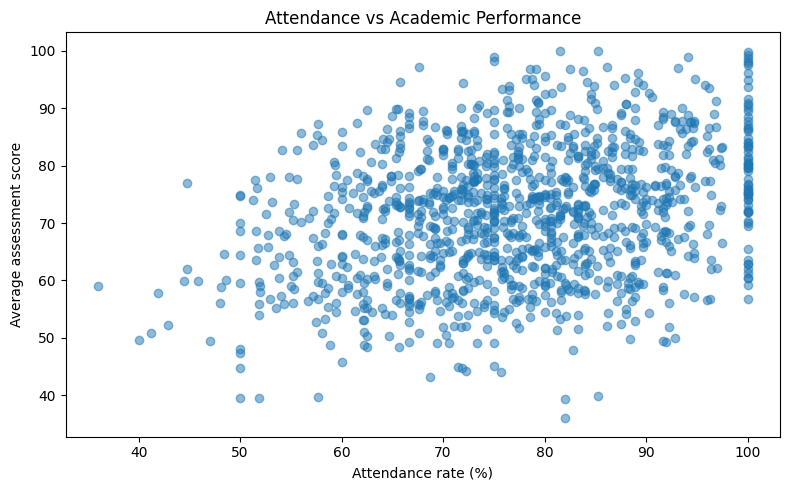

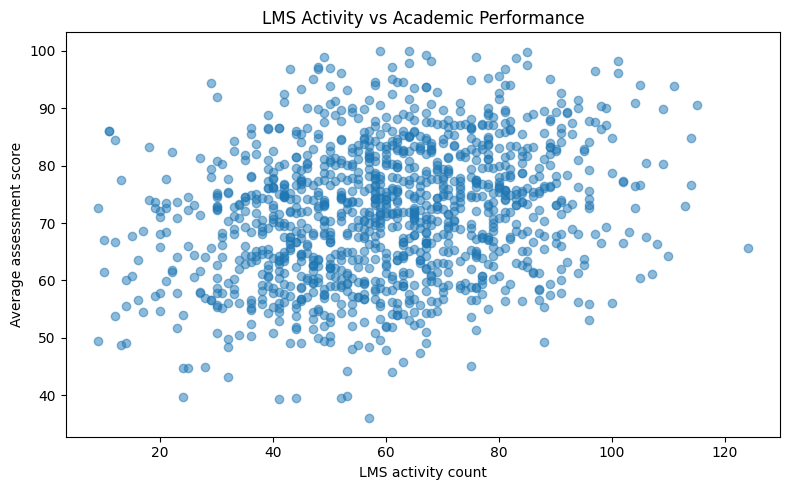

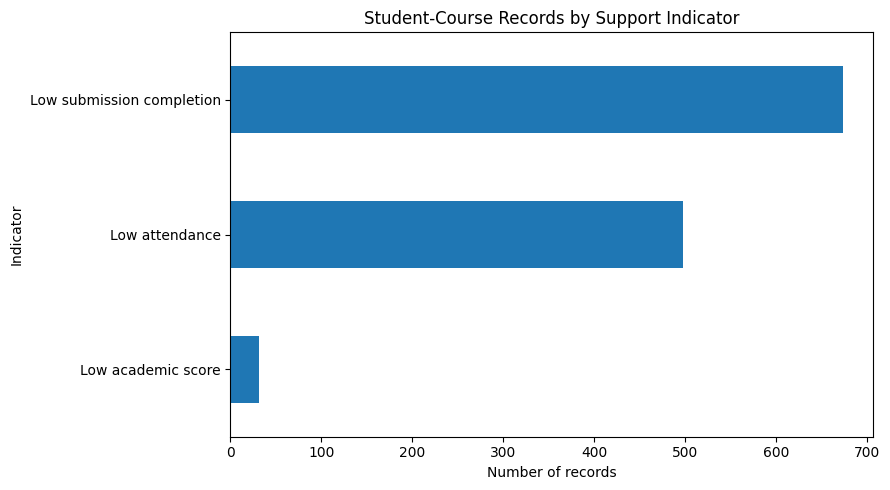


Course-level summary:


,records,average_score,average_attendance,average_completion,records_flagged
course_name,,,,,
Applied Mathematics,147,70.40,76.01,53.85,104
Machine Learning,167,71.19,77.04,57.27,115
Data Analytics,151,71.24,77.61,55.47,101
Data Structures,153,71.66,78.22,53.56,111
Digital Systems,153,71.76,76.76,56.40,108
Programming Fundamentals,136,72.05,77.11,53.99,94
Web Development,140,72.62,77.83,54.71,96
Database Systems,153,72.74,77.21,54.75,113



Correlation between numeric indicators:


,academic_average,attendance_rate,submission_completion_rate,lms_logins,lms_activity_count
academic_average,1.00,0.30,0.25,0.22,0.26
attendance_rate,0.30,1.00,0.25,0.28,0.27
submission_completion_rate,0.25,0.25,1.00,0.37,0.38
lms_logins,0.22,0.28,0.37,1.00,0.41
lms_activity_count,0.26,0.27,0.38,0.41,1.00


In [16]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Keep original columns unchanged
analysis_data = analysis_data.copy()

# Flag inconsistent late-submission records
invalid_late = (
    analysis_data["late_submissions"]
    > analysis_data["submissions_completed"]
)

analysis_data["late_submission_rate"] = np.nan

valid_late = (
    ~invalid_late
    & (analysis_data["submissions_completed"] > 0)
)

analysis_data.loc[valid_late, "late_submission_rate"] = (
    100
    * analysis_data.loc[valid_late, "late_submissions"]
    / analysis_data.loc[valid_late, "submissions_completed"]
)

print("Records excluded from late-rate calculation:", int(invalid_late.sum()))
print("Valid late-rate records:", int(valid_late.sum()))
print(
    "Mean late-submission rate among valid records:",
    round(analysis_data["late_submission_rate"].mean(), 2),
    "%"
)

# Count unique students needing support
flagged_students = analysis_data.loc[
    analysis_data["support_review_flag"], "student_id"
].nunique()

print("\nUnique students with at least one support-review flag:",
      flagged_students, "out of",
      analysis_data["student_id"].nunique())

# -----------------------------------------
# VISUALIZATION 1: Average academic score by course
# -----------------------------------------
course_performance = (
    analysis_data.groupby(["course_code", "course_name"])
    ["academic_average"].mean()
    .sort_values()
)

plt.figure(figsize=(10, 5))
course_performance.plot(kind="barh")
plt.title("Average Academic Performance by Course")
plt.xlabel("Average score")
plt.ylabel("Course")
plt.tight_layout()
plt.show()

# -----------------------------------------
# VISUALIZATION 2: Attendance vs academic score
# -----------------------------------------
plt.figure(figsize=(8, 5))
plt.scatter(
    analysis_data["attendance_rate"],
    analysis_data["academic_average"],
    alpha=0.5
)
plt.title("Attendance vs Academic Performance")
plt.xlabel("Attendance rate (%)")
plt.ylabel("Average assessment score")
plt.tight_layout()
plt.show()

# -----------------------------------------
# VISUALIZATION 3: LMS activity vs academic score
# -----------------------------------------
plt.figure(figsize=(8, 5))
plt.scatter(
    analysis_data["lms_activity_count"],
    analysis_data["academic_average"],
    alpha=0.5
)
plt.title("LMS Activity vs Academic Performance")
plt.xlabel("LMS activity count")
plt.ylabel("Average assessment score")
plt.tight_layout()
plt.show()

# -----------------------------------------
# VISUALIZATION 4: Support-review indicators
# -----------------------------------------
flag_counts = pd.Series({
    "Low attendance": analysis_data["low_attendance_flag"].sum(),
    "Low submission completion": analysis_data["low_completion_flag"].sum(),
    "Low academic score": analysis_data["low_score_flag"].sum()
})

plt.figure(figsize=(9, 5))
flag_counts.sort_values().plot(kind="barh")
plt.title("Student-Course Records by Support Indicator")
plt.xlabel("Number of records")
plt.ylabel("Indicator")
plt.tight_layout()
plt.show()

# -----------------------------------------
# SUMMARY TABLE FOR THE REPORT
# -----------------------------------------
print("\nCourse-level summary:")
display(
    analysis_data.groupby("course_name").agg(
        records=("student_id", "size"),
        average_score=("academic_average", "mean"),
        average_attendance=("attendance_rate", "mean"),
        average_completion=("submission_completion_rate", "mean"),
        records_flagged=("support_review_flag", "sum")
    ).round(2).sort_values("average_score")
)

print("\nCorrelation between numeric indicators:")
display(
    analysis_data[
        [
            "academic_average",
            "attendance_rate",
            "submission_completion_rate",
            "lms_logins",
            "lms_activity_count"
        ]
    ].corr().round(2)
)


In [17]:

# Count risk signals per student-course record
risk_columns = [
    "low_attendance_flag",
    "low_completion_flag",
    "low_score_flag"
]

analysis_data["risk_signal_count"] = (
    analysis_data[risk_columns].fillna(False).astype(int).sum(axis=1)
)

# A more selective review indicator
analysis_data["priority_review_flag"] = (
    analysis_data["risk_signal_count"] >= 2
)

print("Student-course records by number of risk signals:")
display(
    analysis_data["risk_signal_count"]
    .value_counts()
    .sort_index()
    .rename_axis("Risk_Signals")
    .to_frame("Record_Count")
)

print("\nPriority student-course records:",
      int(analysis_data["priority_review_flag"].sum()))

print("\nUnique students with at least one priority record:",
      analysis_data.loc[
          analysis_data["priority_review_flag"], "student_id"
      ].nunique())

# Student-level summary
student_summary = analysis_data.groupby("student_id").agg(
    average_score=("academic_average", "mean"),
    average_attendance=("attendance_rate", "mean"),
    average_completion=("submission_completion_rate", "mean"),
    courses_with_priority_flags=("priority_review_flag", "sum")
).round(2)

student_summary = student_summary.sort_values(
    ["courses_with_priority_flags", "average_score"],
    ascending=[False, True]
)

print("\nStudents to review first:")
display(student_summary.head(15))

# Save analysis outputs
analysis_data.to_csv("student_academic_insight_cleaned.csv", index=False)
student_summary.to_csv("student_level_summary.csv")

print("\nSaved:")
print("student_academic_insight_cleaned.csv")
print("student_level_summary.csv")


Student-course records by number of risk signals:


,Record_Count
Risk_Signals,
0,358
1,502
2,321
3,19



Priority student-course records: 340

Unique students with at least one priority record: 161

Students to review first:


,average_score,average_attendance,average_completion,courses_with_priority_flags
student_id,,,,
STU0136,64.70,60.82,41.02,6
STU0055,57.49,58.90,35.01,5
STU0200,60.77,57.04,37.66,5
STU0020,61.05,62.05,45.06,5
STU0048,71.93,65.93,22.86,5
STU0226,78.10,59.02,32.46,5
STU0221,82.08,67.42,42.67,5
STU0145,51.31,58.77,50.46,4
STU0236,57.32,60.59,58.93,4



Saved:
student_academic_insight_cleaned.csv
student_level_summary.csv


Priority review by course:


,total_records,priority_records,average_score,priority_rate_pct
course_name,,,,
Applied Mathematics,147,51,70.40,34.69
Programming Fundamentals,136,46,72.05,33.82
Database Systems,153,46,72.74,30.07
Web Development,140,40,72.62,28.57
Data Analytics,151,39,71.24,25.83
Machine Learning,167,43,71.19,25.75
Data Structures,153,38,71.66,24.84
Digital Systems,153,37,71.76,24.18


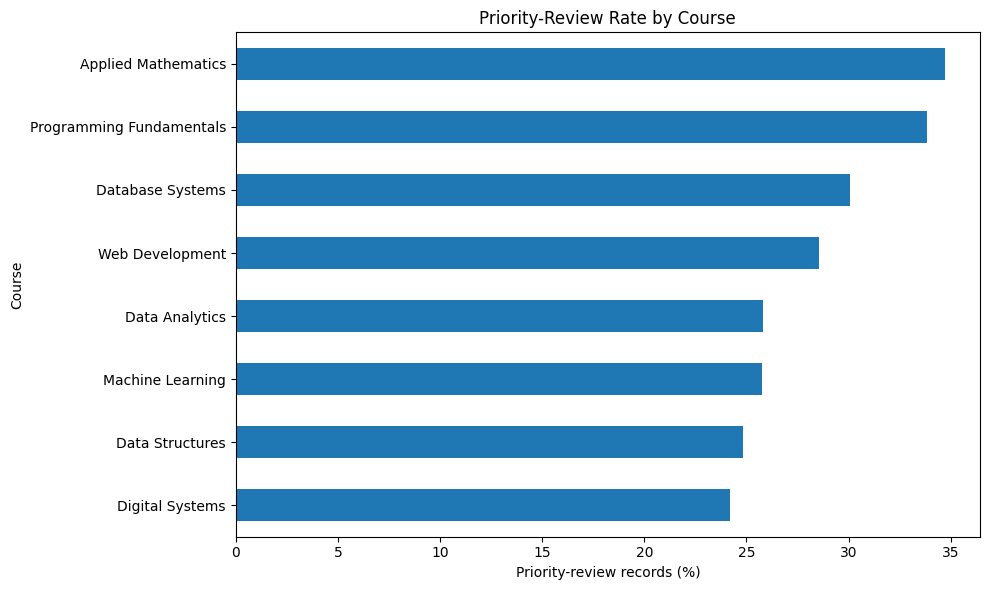


Priority review by programme:


,total_records,priority_records,average_score,priority_rate_pct
programme,,,,
AIML,300,91,72.28,30.33
CSE,404,101,70.63,25.00
ECE,258,78,72.42,30.23
IT,238,70,71.98,29.41


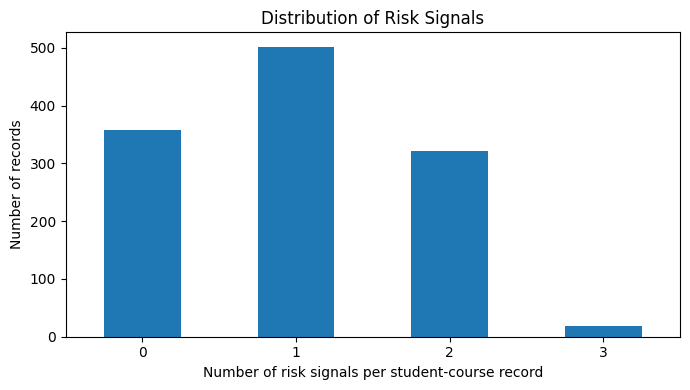


Exported course and programme summaries.


In [18]:

import matplotlib.pyplot as plt
import pandas as pd

# 1. Priority-review records by course
course_priority = (
    analysis_data.groupby("course_name")
    .agg(
        total_records=("student_id", "size"),
        priority_records=("priority_review_flag", "sum"),
        average_score=("academic_average", "mean")
    )
)

course_priority["priority_rate_pct"] = (
    100 * course_priority["priority_records"]
    / course_priority["total_records"]
)

course_priority = course_priority.sort_values(
    "priority_rate_pct", ascending=False
)

print("Priority review by course:")
display(course_priority.round(2))

plt.figure(figsize=(10, 6))
course_priority["priority_rate_pct"].sort_values().plot(kind="barh")
plt.title("Priority-Review Rate by Course")
plt.xlabel("Priority-review records (%)")
plt.ylabel("Course")
plt.tight_layout()
plt.show()

# 2. Priority-review records by programme
programme_priority = (
    analysis_data.groupby("programme")
    .agg(
        total_records=("student_id", "size"),
        priority_records=("priority_review_flag", "sum"),
        average_score=("academic_average", "mean")
    )
)

programme_priority["priority_rate_pct"] = (
    100 * programme_priority["priority_records"]
    / programme_priority["total_records"]
)

print("\nPriority review by programme:")
display(programme_priority.round(2))

# 3. Distribution of risk signals
risk_distribution = (
    analysis_data["risk_signal_count"]
    .value_counts()
    .reindex([0, 1, 2, 3], fill_value=0)
)

plt.figure(figsize=(7, 4))
risk_distribution.plot(kind="bar")
plt.title("Distribution of Risk Signals")
plt.xlabel("Number of risk signals per student-course record")
plt.ylabel("Number of records")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

# 4. Export tables for the assessment submission
course_priority.to_csv("course_priority_summary.csv")
programme_priority.to_csv("programme_priority_summary.csv")

print("\nExported course and programme summaries.")


# **RANDOM FOREST**

In [19]:

import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Target: average assessment score
target = "academic_average"

# Use only attendance, engagement, and course information as inputs
numeric_features = [
    "attendance_rate",
    "submission_completion_rate",
    "lms_logins",
    "lms_activity_count",
    "semester",
    "credits"
]

categorical_features = [
    "course_code",
    "course_type",
    "programme"
]

features = numeric_features + categorical_features

model_data = analysis_data[features + [target]].dropna().copy()

X = model_data[features]
y = model_data[target]

# Split before training
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42
)

# Preprocessing
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])

# Model
model = Pipeline([
    ("preprocessor", preprocessor),
    ("regressor", RandomForestRegressor(
        n_estimators=300,
        random_state=42,
        min_samples_leaf=3
    ))
])

model.fit(X_train, y_train)
predictions = model.predict(X_test)

# Actual test-set performance
mae = mean_absolute_error(y_test, predictions)
rmse = np.sqrt(mean_squared_error(y_test, predictions))
r2 = r2_score(y_test, predictions)

print("MODEL: Random Forest Regressor")
print("Training records:", len(X_train))
print("Testing records:", len(X_test))
print("MAE:", round(mae, 2))
print("RMSE:", round(rmse, 2))
print("R-squared:", round(r2, 3))


MODEL: Random Forest Regressor
Training records: 960
Testing records: 240
MAE: 9.25
RMSE: 11.31
R-squared: 0.118


In [20]:

from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

baseline = DummyRegressor(strategy="mean")
baseline.fit(X_train, y_train)

baseline_predictions = baseline.predict(X_test)

print("BASELINE MODEL")
print("MAE:", round(mean_absolute_error(y_test, baseline_predictions), 2))
print("RMSE:", round(np.sqrt(mean_squared_error(y_test, baseline_predictions)), 2))
print("R-squared:", round(r2_score(y_test, baseline_predictions), 3))


BASELINE MODEL
MAE: 9.98
RMSE: 12.07
R-squared: -0.004
